In [1]:
# Load basic libraries
import os, json, re, operator, duckdb
from dotenv import load_dotenv
import pandas as pd
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from IPython.display import Image

# Load and setup environent vriables
load_dotenv(".env")
model_sql = ChatOpenAI(api_key=os.getenv("API_KEY"),model='gpt-4o-mini',temperature=0)

In [2]:
parientData = pd.read_csv('patient_data.csv')
parientData['last_visit_date'] = pd.to_datetime(parientData['last_visit_date'])
parientData['next_scheduled_visit'] = pd.to_datetime(parientData['next_scheduled_visit'])

parientData['last_visit_date_weekday'] = parientData['last_visit_date'].dt.day_name()
parientData['next_scheduled_visit_weekday'] = parientData['next_scheduled_visit'].dt.day_name()

parientData['age_group'] = pd.cut(parientData["age"],bins=[0, 17, 34, 49, 64, 120],labels=["0-17", "18-34", "35-49", "50-64", "65+"])
parientData.head()

,patient_id,patient_name,age,gender,diagnosis,current_medication,lab_test,lab_value,lab_unit,last_visit_date,...,days_since_last_visit,missed_last_appointment,vitals_bp_systolic,vitals_bp_diastolic,vitals_heart_rate,vitals_spo2,notes,last_visit_date_weekday,next_scheduled_visit_weekday,age_group
0,P0001,Aarav Sharma,68,Male,Type 2 Diabetes,Metformin 500mg,HbA1c,9.9,%,2024-04-24,...,251,No,174,70,95,96,Patient reports good medication adherence.,Wednesday,Saturday,65+
1,P0002,Priya Patel,29,Male,Heart Failure,Furosemide 40mg,BNP,317.6,pg/mL,2024-01-14,...,352,No,174,91,72,97,Patient reports no new symptoms.,Sunday,Wednesday,18-34
2,P0003,Rohan Mehta,45,Male,"Type 2 Diabetes, CKD","Insulin Glargine 10U, Losartan 50mg",HbA1c,11.4,%,2024-08-04,...,149,No,132,86,64,91,Medication dose adjusted this visit.,Sunday,Thursday,35-49
3,P0004,Anjali Singh,34,Female,"COPD, Heart Failure","Tiotropium 18mcg, Furosemide 40mg",FEV1%,33.8,%,2024-01-23,...,343,No,153,70,93,94,Patient reports no new symptoms.,Tuesday,Monday,18-34
4,P0005,Vikram Nair,51,Male,"Hypertension, Heart Failure","Amlodipine 5mg, Furosemide 40mg",BP Systolic,124.9,mmHg,2024-04-26,...,249,No,134,71,82,94,Patient education provided on diet and lifestyle.,Friday,Tuesday,50-64


In [3]:
def task_1(question: str) -> dict:
    query_con = duckdb.connect(":memory:")
    query_con.register("patients", parientData)
    schema = query_con.execute("DESCRIBE patients").df().to_string(index=False)

    sql_response = model_sql.invoke([
        SystemMessage(content=f"""
            Generate one read-only DuckDB SQL query for the patients table.
            Schema: {schema}
            Rules:
            - Return SQL only, no explanations or Markdown.
            - Start with SELECT or WITH.
            - Use only existing columns and valid DuckDB syntax.
            - Never modify data.
            - `missed_last_appointment` is a timestamp flag, not appointment history.
            - If the question cannot be answered from the schema, return a SELECT query explaining the limitation.
            """),
        HumanMessage(content=question)
    ])
    sql_query = sql_response.content.strip().removeprefix("```sql").removesuffix("```").strip()

    results = query_con.execute(sql_query).df().to_dict(orient="records")
    query_con.close()
    answer_response = model_sql.invoke([
        SystemMessage(content="Answer concisely using only the SQL results. Do not invent findings."),
        HumanMessage(content=f"Question: {question}\nResults: {json.dumps(results, default=str)}")
        ])
    
    total_token = answer_response.usage_metadata.get("total_tokens") + sql_response.usage_metadata.get("total_tokens")
    print(f"---------Total Tokens used:- {total_token}, sql:- {sql_response.usage_metadata.get("total_tokens")} llm:- {answer_response.usage_metadata.get("total_tokens")}")
    return {
        "sql_query": sql_query,
        "results": results,
        "answer": answer_response.content
    }

In [4]:
# Testing Task 1
response = task_1("which diagnosis has the highest missed appointment percentage?")
print(response["answer"])

---------Total Tokens used:- 591, sql:- 511 llm:- 80
The diagnosis with the highest missed appointment percentage is Hypertension, with a percentage of 40.0%.


In [ ]:
# Task 2
@tool
def get_patient_data(patient_id: str) -> dict:
    """Retrieve a patient's complete record using their patient ID."""
    print("-----TOOL-----get_patient_data")
    patient = parientData[parientData["patient_id"] == patient_id]
    if patient.empty:
        return {"error": "Patient not found"}
    return patient.iloc[0].to_dict()

@tool
def get_missed_appointment_patients() -> list:
    """Retrieve patients marked as having missed their last appointment."""
    print("-----TOOL-----get_missed_appointment_patients")
    patients = parientData[parientData["missed_last_appointment"] == "Yes"][['patient_id', 'patient_name', 'age', 'gender', 'diagnosis','current_medication','notes']]
    return patients.to_dict(orient="records")

@tool
def get_patient_followup_context(patient_id: str) -> dict:
    """Get follow-up relevant details for a patient, including diagnosis,
    medication, lab results, notes, and next scheduled visit."""
    print("-----TOOL-----get_patient_followup_context")
    patient = get_patient_data.invoke({"patient_id": patient_id})
    if "error" in patient:
        return patient
    fields = [
        "patient_id", "patient_name", "diagnosis",
        "current_medication", "lab_test", "lab_value",
        "lab_unit", "last_visit_date", "next_scheduled_visit",
        "days_since_last_visit", "missed_last_appointment",
        "vitals", "notes"
    ]
    return {key: patient.get(key) for key in fields}

@tool
def filter_patient_diagnosis_data(diagnoses: list[str]) -> dict:
    """Find patient IDs matching for one or more diagnoses use for requests"""
    print("-----TOOL-----filter_patient_data")
    filtered = parientData[parientData["diagnosis"].str.contains("|".join(diagnoses),case=False,na=False,regex=True)]
    filtered = filtered[['patient_id', 'age', 'gender', 'diagnosis', 'missed_last_appointment']]
    
    return filtered.to_dict(orient="records")

@tool
def analyze_dataset(question: str) -> dict:
    """this tool is used for EDA with DuckDB SQL query in the database."""
    print("-----TOOL-----EDA ")
    return task_1(question)
tools = [get_patient_data,get_missed_appointment_patients,get_patient_followup_context,analyze_dataset,filter_patient_diagnosis_data]

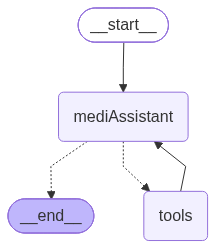

In [ ]:
class MedicareState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
llm_with_tools = model_sql.bind_tools(tools)

def mediAssistant(state: MedicareState):
    response = llm_with_tools.invoke([
        SystemMessage(content="""
        you are a agent at MediCare and your task is to do data analysis assistant.

        Decide what to do for each user message:

        - General questions: answer directly without tools.
        - Dataset-wide EDA, counts, statistics, comparisons, trends, and diagnosis analysis across patients: use analyze_dataset.
        - Individual patient queries: use get_patient_data.
        - Patient follow-up questions and suggestions: use get_patient_followup_context and provide practical, data-based guidance.
        - Missed appointment queries: use get_missed_appointment_patients.
        - Patient filtering requests on the basis of diagnosis: use filter_patient_diagnosis_data.
        - Follow-up questions: use conversation history to understand context.
        - Ambiguous requests: ask for clarification.
        - Call multiple tools when necessary and summarize their results.

        Response rules:
        - Use tool results as evidence; never invent patient data, diagnoses, or historical appointment counts.
        - Provide specific, actionable follow-up suggestions based on recorded patient data.
        - Do not replace answers with generic disclaimers or refuse routine follow-up assistance.
        - Do not diagnose conditions or prescribe medications.
        - Keep responses concise and structured, with each item on a new line.
        """),
        *state["messages"]
    ])
    print(f"---------Total Tokens used:- {response.usage_metadata.get('total_tokens')}")
    return {"messages": [response]}


def route_request(state: MedicareState):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END


graph = StateGraph(MedicareState)

graph.add_node("mediAssistant", mediAssistant)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "mediAssistant")
graph.add_conditional_edges("mediAssistant",route_request,{"tools": "tools", END: END})
graph.add_edge("tools", "mediAssistant")

workflow = graph.compile()
Image(workflow.get_graph().draw_mermaid_png())

In [7]:
chat_history = []

def chat(user_message: str):
    global chat_history

    chat_history.append(HumanMessage(content=user_message))

    result = workflow.invoke({"messages": chat_history})

    chat_history = result["messages"]

    return chat_history[-1].content

In [8]:
# Testing Task 1 / task 2/ task 3
print(chat("Analyze the dataset, tell me on which day of the week a customer is more likly to miss an appointment?"))

---------Total Tokens used:- 473
-----TOOL-----EDA 
---------Total Tokens used:- 686, sql:- 508 llm:- 178
---------Total Tokens used:- 762
Patients are more likely to miss their appointments on the following days of the week:

- **Friday**: 4 missed appointments
- **Tuesday**: 3 missed appointments
- **Thursday**: 3 missed appointments
- **Wednesday**: 2 missed appointments
- **Sunday**: 2 missed appointments
- **Saturday**: 1 missed appointment

Overall, Friday has the highest missed appointment count.


In [9]:
print(chat("which diagnosis has the highest missed appointment percentage?"))

---------Total Tokens used:- 802
-----TOOL-----EDA 
---------Total Tokens used:- 995, sql:- 499 llm:- 496
---------Total Tokens used:- 1372
The diagnosis with the highest percentage of missed appointments is:

- **Heart Failure**: 25% (3 out of 12 patients)

This indicates that patients diagnosed with Heart Failure have the highest likelihood of missing their appointments compared to other diagnoses.


In [10]:
# getting detials of a patient from task 4 - Single Patient Analysis 
print(chat("Now show me patient P0003's details."))

---------Total Tokens used:- 1407
-----TOOL-----get_patient_data
---------Total Tokens used:- 1889
Here are the details for patient **Rohan Mehta** (Patient ID: P0003):

- **Age**: 45
- **Gender**: Male
- **Diagnosis**: Type 2 Diabetes, CKD
- **Current Medication**: 
  - Insulin Glargine 10U
  - Losartan 50mg
- **Lab Test**: HbA1c
- **Lab Value**: 11.4% 
- **Last Visit Date**: August 4, 2024
- **Next Scheduled Visit**: October 3, 2024
- **Days Since Last Visit**: 149 days
- **Missed Last Appointment**: No
- **Vitals**:
  - Blood Pressure: 132/86 mmHg
  - Heart Rate: 64 bpm
  - SpO2: 91%
- **Notes**: Medication dose adjusted this visit.
- **Last Visit Day**: Sunday
- **Next Scheduled Visit Day**: Thursday
- **Age Group**: 35-49

If you need further information or follow-up suggestions, feel free to ask!


In [11]:
print(chat("What follow-up would you suggest for this patient?"))

---------Total Tokens used:- 1926
-----TOOL-----get_patient_followup_context
-----TOOL-----get_patient_data
---------Total Tokens used:- 2373
For patient **Rohan Mehta** (Type 2 Diabetes, CKD), here are the suggested follow-up actions:

1. **Monitor HbA1c Levels**: 
   - The current HbA1c level is 11.4%, which indicates poor glycemic control. Regular monitoring is essential to assess the effectiveness of the current treatment plan.

2. **Medication Review**:
   - Since the medication dose was adjusted during the last visit, ensure that Rohan is adhering to the new regimen of Insulin Glargine and Losartan. Discuss any side effects or concerns he may have.

3. **Lifestyle Modifications**:
   - Encourage Rohan to maintain a balanced diet and engage in regular physical activity to help manage his diabetes and CKD.

4. **Next Scheduled Visit**:
   - Remind him of the upcoming appointment on October 3, 2024, and emphasize the importance of attending this visit for ongoing management.

5. **E

In [12]:
print(chat("give patient id where Missed Last Appointment is yes"))

---------Total Tokens used:- 2405
-----TOOL-----get_missed_appointment_patients
---------Total Tokens used:- 3715
Here are the patient IDs of individuals who missed their last appointment:

1. **P0018** - Lakshmi Menon (Heart Failure)
2. **P0031** - Harish Bajaj (Chronic Kidney Disease)
3. **P0036** - Vandana Srivastava (Type 2 Diabetes)
4. **P0041** - Tarun Mukherjee (Hypertension)
5. **P0043** - Gaurav Dey (Hypertension, Anemia)
6. **P0058** - Hina Akhtar (Heart Failure)
7. **P0062** - Mary Joseph (Asthma)
8. **P0063** - John Fernandez (Hypertension)
9. **P0066** - Angela Pereira (Type 2 Diabetes, CKD)
10. **P0069** - Victor Lobo (Type 2 Diabetes)
11. **P0070** - Teresa Dias (Osteoarthritis)
12. **P0076** - Parmjit Hundal (Depression)
13. **P0081** - Nandini Rao (Hypothyroidism)
14. **P0098** - Mrinal Basu (Heart Failure)
15. **P0099** - Paramita Chatterjee (Type 2 Diabetes, Hypertension)

If you need more information about any specific patient, feel free to ask!


In [13]:
print(chat("Now show me patient P0018's details."))

---------Total Tokens used:- 3750
-----TOOL-----get_patient_data
---------Total Tokens used:- 4210
Here are the details for patient **Lakshmi Menon** (Patient ID: P0018):

- **Age**: 36
- **Gender**: Female
- **Diagnosis**: Heart Failure
- **Current Medication**: Furosemide 40mg
- **Lab Test**: BNP
- **Lab Value**: 952.3 pg/mL
- **Last Visit Date**: July 27, 2024
- **Next Scheduled Visit**: September 10, 2024
- **Days Since Last Visit**: 157 days
- **Missed Last Appointment**: Yes
- **Vitals**:
  - Blood Pressure: 160/87 mmHg
  - Heart Rate: 85 bpm
  - SpO2: 96%
- **Notes**: Patient education provided on diet and lifestyle.
- **Last Visit Day**: Saturday
- **Next Scheduled Visit Day**: Tuesday
- **Age Group**: 35-49

If you need further information or follow-up suggestions for this patient, feel free to ask!


In [14]:
print(chat("What follow-up would you suggest for this patient?"))

---------Total Tokens used:- 4247
-----TOOL-----get_patient_followup_context
-----TOOL-----get_patient_data
---------Total Tokens used:- 4689
For patient **Lakshmi Menon** (Heart Failure), here are the suggested follow-up actions:

1. **Review Lab Results**:
   - The BNP level is 952.3 pg/mL, which indicates potential heart failure exacerbation. This should be closely monitored and discussed during the next visit.

2. **Medication Adherence**:
   - Ensure that Lakshmi is taking her medication (Furosemide 40mg) as prescribed. Discuss any side effects or concerns she may have regarding her medication.

3. **Monitor Symptoms**:
   - Encourage Lakshmi to monitor for any worsening symptoms such as shortness of breath, swelling in the legs, or fatigue. Advise her to report any significant changes immediately.

4. **Lifestyle Modifications**:
   - Reinforce the importance of dietary changes, including sodium restriction and fluid management, as well as regular physical activity as tolerated.


In [15]:
print(chat("prepare a small follow-up care message to be sent to this patient mentioning next scheduled visit"))

---------Total Tokens used:- 4851
Here's a follow-up care message for patient **Lakshmi Menon**:

---

**Dear Lakshmi Menon,**

We hope this message finds you well. We wanted to remind you of your upcoming appointment scheduled for **September 10, 2024**. It is important to attend this visit to reassess your heart failure management and discuss any concerns you may have.

Please continue to monitor your symptoms and adhere to your medication regimen. If you experience any worsening symptoms or have questions before your appointment, do not hesitate to reach out.

Thank you for taking care of your health!

Best regards,  
[Your Healthcare Team]

--- 

Feel free to customize it further if needed!


In [16]:
print(chat("find all patient with any of these Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia"))

---------Total Tokens used:- 4913
-----TOOL-----filter_patient_data
---------Total Tokens used:- 9695
Here are the patients with any of the following diagnoses: Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia:

1. **P0001** - Age: 68, Gender: Male, Diagnosis: Type 2 Diabetes, Missed Last Appointment: No
2. **P0002** - Age: 29, Gender: Male, Diagnosis: Heart Failure, Missed Last Appointment: No
3. **P0003** - Age: 45, Gender: Male, Diagnosis: Type 2 Diabetes, CKD, Missed Last Appointment: No
4. **P0004** - Age: 34, Gender: Female, Diagnosis: COPD, Heart Failure, Missed Last Appointment: No
5. **P0005** - Age: 51, Gender: Male, Diagnosis: Hypertension, Heart Failure, Missed Last Appointment: No
6. **P0007** - Age: 57, Gender: Female, Diagnosis: COPD, Missed Last Appointment: No
7. **P0008** - Age: 45, Gender: Male, Diagnosis: Heart Failure, Missed Last Appointment: No
8. **P0009** - Age: 36, Gender: Male, Diagnosis: Hypertension, Heart Failure, Missed Last Appointment: No


In [17]:
print(chat("please share me these id's"))

---------Total Tokens used:- 10153
Here are the patient IDs for those with any of the specified diagnoses (Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia):

1. P0001
2. P0002
3. P0003
4. P0004
5. P0005
6. P0007
7. P0008
8. P0009
9. P0010
10. P0014
11. P0016
12. P0017
13. P0018
14. P0019
15. P0021
16. P0022
17. P0023
18. P0024
19. P0029
20. P0030
21. P0032
22. P0034
23. P0035
24. P0036
25. P0037
26. P0038
27. P0040
28. P0041
29. P0043
30. P0045
31. P0046
32. P0047
33. P0048
34. P0050
35. P0051
36. P0053
37. P0055
38. P0056
39. P0058
40. P0060
41. P0063
42. P0065
43. P0066
44. P0068
45. P0069
46. P0073
47. P0074
48. P0077
49. P0078
50. P0079
51. P0080
52. P0083
53. P0084
54. P0085
55. P0088
56. P0089
57. P0090
58. P0091
59. P0092
60. P0093
61. P0095
62. P0096
63. P0097
64. P0098
65. P0099
66. P0100

If you need any further assistance or details about these patients, just let me know!
